# Multi-head ABSA with a 0-4 rating head

In this notebook I train an aspect-based sentiment model on the laptop reviews. For each sentence it predicts the (category, attribute) opinions and gives each one a rating from 0 to 4, which I then map to negative, neutral or positive.

**Data.** `train_final.csv` with the columns `sentence_id, review_id, split, text, prev_text, next_text, category, attribute, polarity`, where `polarity` is already a 0-4 rating (negative 0, neutral 2, positive 4). I drop the rows without an opinion.

**Model.** One shared encoder with four heads on top:

| head | output | what it predicts |
|---|---|---|
| `category_head` | `[B, C]` | which categories are mentioned (multi-label) |
| `attribute_head` | `[B, A]` | which attributes are mentioned (multi-label) |
| `pair_head` | `[B, C, A]` | whether each category#attribute opinion is present |
| `rating_head` | `[B, C, A, 5]` | a 0-4 rating distribution for every pair |

A prediction is a triple `(category, attribute, rating)`. For the polarity I compare the expected rating `r` with two cut-offs: `r < lo` is negative, `lo <= r <= hi` neutral and `r > hi` positive, and a low-confidence opinion becomes neutral. I tune `lo`, `hi` and `min_conf` on validation.

**Splits.** If the `split` column has a `test` value I use the splits as given. Otherwise I group the reviews into `n_folds` folds by `review_id`, so no review is in more than one of train, validation and test. `run_mode="single"` holds out one fold, `"cv"` runs them all.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("transformers") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "transformers"])
import transformers; print("transformers", transformers.__version__)

transformers 5.20.2


## 1. Config

All settings are in `CFG`, so this is the only cell I edit between runs. The cell also sets up logging (to `train.log` and the screen), the seed and the device. This run was on a Tesla T4.

In [2]:
import os, json, random, time, logging, shutil
from types import SimpleNamespace
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import (precision_recall_fscore_support, average_precision_score, roc_auc_score,
                             confusion_matrix, f1_score, cohen_kappa_score)
from scipy.stats import spearmanr
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
try: display
except NameError: display = print

CFG = SimpleNamespace(
    data_path="train_final.csv",
    model_name="BAAI/bge-small-en-v1.5",
    trust_remote_code=False,
    output_dir="absa_results",
    save_to_drive=False,                   # True: save results to Google Drive so they survive a Colab disconnect
    debug=False,                           # True: quick end-to-end check on 400 sentences, 2 epochs
    # ---- splits
    split_mode="auto",                     # "auto": the given splits if there is a test split, else folds. Or force "folds" / "predefined"
    n_folds=5,
    run_mode="single",                     # "single" holds out test_fold, "cv" runs every fold
    test_fold=0,
    val_ratio=0.12,                        # share of training reviews kept for validation, if there's no val split
    use_context=False,                     # add prev_text + next_text as a second segment
    # ---- training
    max_length=128, batch_size=32,
    epochs=15, min_epochs=10,              # no early stopping before min_epochs
    patience=4,
    lr=3e-5, head_lr=1e-3, weight_decay=0.01, warmup_ratio=0.1,
    dropout=0.1, pooling="mean",           # pooling: "mean" or "cls"
    w_cat=1.0, w_attr=1.0, w_pair=1.0, w_rating=1.0,
    n_ratings=5,
    soft_sigma=0.5,                        # width of the soft rating target around the gold rating, 0 = one-hot
    gold_cuts=(1.5, 2.5),                  # gold rating to polarity: below 1.5 negative, 1.5-2.5 neutral, above 2.5 positive
    rating_anchor={"negative": 0, "neutral": 2, "positive": 4},   # only used if the CSV has word labels instead of ratings
    seed=2026, fp16=True,
)

if CFG.save_to_drive:
    from google.colab import drive; drive.mount("/content/drive")
    CFG.output_dir = "/content/drive/MyDrive/absa_results"
out_dir = Path(CFG.output_dir); out_dir.mkdir(parents=True, exist_ok=True)

log = logging.getLogger("absa"); log.setLevel(logging.INFO); log.propagate = False
for h in list(log.handlers): log.removeHandler(h)
fmt = logging.Formatter("%(asctime)s | %(message)s", "%H:%M:%S")
for h in (logging.FileHandler(out_dir / "train.log", encoding="utf-8"), logging.StreamHandler(sys.stdout)):
    h.setFormatter(fmt); log.addHandler(h)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
log.info(f"device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
if device.type == "cpu": log.info("WARNING: no GPU found - training will be slow. Runtime -> Change runtime type -> GPU")

09:45:49 | device: cuda (Tesla T4)


## 2. Load data

I keep only the rows with an opinion and read `polarity` as a 0-4 rating. If a sentence has the same category#attribute twice with different ratings, I average them.

In this run 459 of the 3,345 rows had no opinion, which leaves 2,016 sentences with 2,883 opinions (449 reviews, 22 categories, 9 attributes). The ratings are only 0, 2 and 4, and neutral is rare: 191 of 2,883 opinions, about 7%. Most sentences have a single opinion.

In [3]:
if not os.path.exists(CFG.data_path):
    try:
        from google.colab import files
        up = files.upload(); CFG.data_path = next(iter(up))
    except ImportError:
        raise FileNotFoundError(f"{CFG.data_path} not found")

raw = pd.read_csv(CFG.data_path, keep_default_na=False, dtype=str)
raw.columns = [c.strip() for c in raw.columns]
if "category" not in raw.columns and "entity" in raw.columns: raw = raw.rename(columns={"entity": "category"})
missing = [c for c in ["sentence_id", "text", "category", "attribute", "polarity"] if c not in raw.columns]
if missing: raise ValueError(f"CSV is missing columns {missing}; found {list(raw.columns)}")
if "review_id" not in raw.columns: raw["review_id"] = raw["sentence_id"].str.split(":").str[0]
if "split" not in raw.columns: raw["split"] = "train"
for c in ["prev_text", "next_text"]:
    if c not in raw.columns: raw[c] = ""
for c in raw.columns: raw[c] = raw[c].astype(str).str.strip()
raw["split"] = raw["split"].str.lower().replace({"": "train"})

n_rows, n_sent = len(raw), raw.sentence_id.nunique()
df = raw[(raw.category != "") & (raw.attribute != "") & (raw.polarity != "") & (raw.text != "")].copy()
rating = pd.to_numeric(df.polarity, errors="coerce")
word = df.polarity.str.lower().map(CFG.rating_anchor)
rating = rating.fillna(word)
bad = rating.isna(); out_of_range = (rating < 0) | (rating > CFG.n_ratings - 1)
if bad.any(): log.info(f"dropping {int(bad.sum())} rows with unreadable polarity, e.g. {df.polarity[bad].unique()[:5]}")
if out_of_range.any(): log.info(f"clipping {int(out_of_range.sum())} ratings outside 0..{CFG.n_ratings-1}")
df = df[~bad].copy(); df["rating"] = rating[~bad].round().clip(0, CFG.n_ratings - 1).astype(int)
log.info(f"rows: {n_rows} -> {len(df)} opinion rows (dropped {n_rows - len(df)} rows with no opinion / bad label); sentences {n_sent} -> {df.sentence_id.nunique()}")

examples, n_conflict = [], 0
for sid, g in df.groupby("sentence_id", sort=False):
    r0 = g.iloc[0]; d = {}
    for c, a, r in zip(g.category, g.attribute, g.rating): d.setdefault((c, a), []).append(r)
    n_conflict += sum(len(set(v)) > 1 for v in d.values())
    gold = sorted((c, a, int(round(float(np.mean(v))))) for (c, a), v in d.items())   # conflicting ratings for one pair: take the mean
    examples.append(dict(id=sid, review=r0["review_id"], split=r0["split"], text=r0["text"], prev=r0["prev_text"], next=r0["next_text"], gold=gold))
if n_conflict: log.info(f"{n_conflict} (sentence, category, attribute) pairs had conflicting ratings -> averaged")

if CFG.debug:
    examples = examples[:400]; CFG.epochs, CFG.min_epochs, CFG.patience = 2, 1, 2
    log.info("DEBUG mode: 400 sentences, 2 epochs")

categories = sorted({c for ex in examples for c, _, _ in ex["gold"]})
attributes = sorted({a for ex in examples for _, a, _ in ex["gold"]})
polarities = ["negative", "neutral", "positive"]
LABELS = dict(categories=categories, attributes=attributes, polarities=polarities, ratings=list(range(CFG.n_ratings)))
C, A, P, NR = len(categories), len(attributes), len(polarities), CFG.n_ratings
RATINGS = np.arange(NR)
GOLD3 = np.where(RATINGS < CFG.gold_cuts[0], 0, np.where(RATINGS > CFG.gold_cuts[1], 2, 1))   # gold rating to polarity index

# folds by review, so no review is in two folds
revs = sorted({e["review"] for e in examples}); random.Random(CFG.seed).shuffle(revs)
rev_fold = {r: i % CFG.n_folds for i, r in enumerate(revs)}
for e in examples: e["fold"] = rev_fold[e["review"]]
folds = sorted({e["fold"] for e in examples})

print(f"\n{len(examples)} sentences | {sum(len(e['gold']) for e in examples)} opinions | {C} categories | {A} attributes | {len(revs)} reviews")
print("split column:", dict(pd.Series([e["split"] for e in examples]).value_counts()))
rc = pd.Series([r for e in examples for *_, r in e["gold"]]).value_counts().sort_index()
print("rating distribution:", dict(rc)); print("polarity (gold cuts) distribution:", {polarities[k]: int(rc[[i for i in rc.index if GOLD3[i] == k]].sum()) for k in range(P)})
print("opinions per sentence:", dict(pd.Series([len(e["gold"]) for e in examples]).value_counts().sort_index()))
print("\ncategories:", categories); print("attributes:", attributes)

09:45:49 | rows: 3345 -> 2886 opinion rows (dropped 459 rows with no opinion / bad label); sentences 2475 -> 2016
09:45:49 | 3 (sentence, category, attribute) pairs had conflicting ratings -> averaged

2016 sentences | 2883 opinions | 22 categories | 9 attributes | 449 reviews
split column: {'train': np.int64(1719), 'validation': np.int64(297)}
rating distribution: {0: np.int64(1078), 2: np.int64(191), 4: np.int64(1614)}
polarity (gold cuts) distribution: {'negative': 1078, 'neutral': 191, 'positive': 1614}
opinions per sentence: {1: np.int64(1331), 2: np.int64(533), 3: np.int64(126), 4: np.int64(22), 5: np.int64(4)}

categories: ['BATTERY', 'COMPANY', 'CPU', 'DISPLAY', 'FANS_COOLING', 'GRAPHICS', 'HARDWARE', 'HARD_DISC', 'KEYBOARD', 'LAPTOP', 'MEMORY', 'MOTHERBOARD', 'MOUSE', 'MULTIMEDIA_DEVICES', 'OPTICAL_DRIVES', 'OS', 'PORTS', 'POWER_SUPPLY', 'SHIPPING', 'SOFTWARE', 'SUPPORT', 'WARRANTY']
attributes: ['CONNECTIVITY', 'DESIGN_FEATURES', 'GENERAL', 'MISCELLANEOUS', 'OPERATION_PERFORM

## 3. Dataset

Each sentence is tokenised once. The targets are multi-hot vectors for categories and attributes, plus a category × attribute grid with the gold rating in every pair that has an opinion (-100 elsewhere). The pair target is whether a grid cell is filled. Batches are padded to their longest sentence.

In [4]:
def get_tokenizer():
    tok = AutoTokenizer.from_pretrained(CFG.model_name, trust_remote_code=CFG.trust_remote_code)
    if tok.pad_token is None: tok.pad_token = tok.eos_token or tok.unk_token
    return tok

class ABSADataset(Dataset):
    def __init__(self, exs, tok):
        self.exs = exs
        texts = [e["text"] for e in exs]
        pairs = [(e["prev"] + " " + e["next"]).strip() or e["text"] for e in exs] if CFG.use_context else None
        enc = tok(texts, pairs, truncation=True, max_length=CFG.max_length) if pairs else tok(texts, truncation=True, max_length=CFG.max_length)
        self.ids, self.mask = enc["input_ids"], enc["attention_mask"]
        c2i = {v: i for i, v in enumerate(categories)}; a2i = {v: i for i, v in enumerate(attributes)}
        N = len(exs)
        self.cat = np.zeros((N, C), np.float32); self.attr = np.zeros((N, A), np.float32)
        self.pol = np.full((N, C, A), -100, np.int64)          # gold rating per pair, -100 where there's no opinion
        for n, e in enumerate(exs):
            for c, a, r in e["gold"]:
                ci, ai = c2i[c], a2i[a]
                self.cat[n, ci] = 1; self.attr[n, ai] = 1; self.pol[n, ci, ai] = r
        self.pair = (self.pol >= 0).astype(np.float32)
    def __len__(self): return len(self.exs)
    def __getitem__(self, i): return dict(input_ids=self.ids[i], attention_mask=self.mask[i], i=i)

def make_loader(ds, tok, shuffle):
    def collate(items):
        b = tok.pad([{"input_ids": x["input_ids"], "attention_mask": x["attention_mask"]} for x in items], return_tensors="pt")
        idx = np.array([x["i"] for x in items])
        return dict(input_ids=b["input_ids"], attention_mask=b["attention_mask"],
                    cat=torch.from_numpy(ds.cat[idx]), attr=torch.from_numpy(ds.attr[idx]),
                    pair=torch.from_numpy(ds.pair[idx]), pol=torch.from_numpy(ds.pol[idx]))
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle, collate_fn=collate)

## 4. Model

The encoder output is mean-pooled into one sentence vector, and all four heads read it. Category and attribute are single linear layers. The pair and rating heads are small MLPs, because they cover all 22 × 9 = 198 pairs.

The loss adds up four parts: BCE for the category, attribute and pair heads, and cross-entropy for the rating against a soft ordinal target (`soft_sigma`), so a rating that is off by one costs less than one that is off by four. The rating loss only counts gold pairs.

In [5]:
class ABSAModel(nn.Module):
    def __init__(self, model_name, C, A, NR, dropout=0.1, pooling="mean", trust_remote_code=False):
        super().__init__()
        self.C, self.A, self.NR, self.pooling, self.model_name = C, A, NR, pooling, model_name
        self.encoder = AutoModel.from_pretrained(model_name, trust_remote_code=trust_remote_code)
        h = getattr(self.encoder.config, "hidden_size", None) or getattr(self.encoder.config, "d_model")
        self.hidden = h
        self.drop = nn.Dropout(dropout)
        self.category_head = nn.Linear(h, C)
        self.attribute_head = nn.Linear(h, A)
        self.pair_head = nn.Sequential(nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout), nn.Linear(h, C * A))
        self.rating_head = nn.Sequential(nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout), nn.Linear(h, C * A * NR))

    def forward(self, input_ids, attention_mask):
        hid = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        if self.pooling == "cls":
            pooled = hid[:, 0]
        else:
            m = attention_mask.unsqueeze(-1).to(hid.dtype)
            pooled = (hid * m).sum(1) / m.sum(1).clamp_min(1.0)
        pooled = self.drop(pooled); b = pooled.shape[0]
        return dict(category_logits=self.category_head(pooled),
                    attribute_logits=self.attribute_head(pooled),
                    pair_logits=self.pair_head(pooled).view(b, self.C, self.A),
                    rating_logits=self.rating_head(pooled).view(b, self.C, self.A, self.NR))

def describe_model(model):
    n = lambda m: sum(p.numel() for p in m.parameters())
    tot = n(model); enc = n(model.encoder)
    lines = ["", "=" * 78, "CUSTOM ABSA ARCHITECTURE  -  predicted triple: (category, attribute, rating 0-4)", "=" * 78,
             f"encoder : {model.model_name}   hidden={model.hidden}   pooling={model.pooling}   params={enc/1e6:.2f}M",
             f"                |-- {'head':15s} {'output shape':22s} {'params':>9s}   role"]
    rows = [("category_head", f"[B, {model.C}]", model.category_head, "which categories appear (multi-label, BCE)"),
            ("attribute_head", f"[B, {model.A}]", model.attribute_head, "which attributes appear (multi-label, BCE)"),
            ("pair_head", f"[B, {model.C}, {model.A}]", model.pair_head, "is category#attribute opinion present (BCE)"),
            ("rating_head", f"[B, {model.C}, {model.A}, {model.NR}]", model.rating_head, "rating 0-4 distribution per pair (soft-ordinal CE)")]
    for name, shp, mod, role in rows:
        lines.append(f"                |-- {name:15s} {shp:22s} {n(mod):>9,d}   {role}")
    lines += [f"total params {tot/1e6:.2f}M (encoder {enc/1e6:.2f}M, heads {(tot-enc)/1e6:.2f}M) | trainable {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.2f}M",
              "decoding: pair prob >= pair_thr -> opinion; expected rating r = sum(k*p_k); r<lo negative | lo<=r<=hi neutral | r>hi positive; low confidence -> neutral",
              "=" * 78]
    log.info("\n".join(lines))
    log.info("module detail:\n" + "\n".join(f"{nm}: {repr(m)}" for nm, m in [("category_head", model.category_head), ("attribute_head", model.attribute_head), ("pair_head", model.pair_head), ("rating_head", model.rating_head)]))

def soft_table():
    """Soft rating targets: row k is the target distribution for gold rating k."""
    k = np.arange(NR)
    if CFG.soft_sigma <= 0: return torch.eye(NR)
    t = np.exp(-((k[None, :] - k[:, None]) ** 2) / (2 * CFG.soft_sigma ** 2))
    return torch.tensor(t / t.sum(1, keepdims=True), dtype=torch.float32)

def compute_loss(out, batch, pair_pos_weight=None, rating_w=None, table=None):
    F = nn.functional
    l_cat = F.binary_cross_entropy_with_logits(out["category_logits"].float(), batch["cat"])
    l_attr = F.binary_cross_entropy_with_logits(out["attribute_logits"].float(), batch["attr"])
    l_pair = F.binary_cross_entropy_with_logits(out["pair_logits"].float(), batch["pair"], pos_weight=pair_pos_weight)
    logits = out["rating_logits"].float().reshape(-1, out["rating_logits"].shape[-1])
    tgt = batch["pol"].reshape(-1); valid = tgt.ne(-100)
    if valid.any():
        logp = F.log_softmax(logits[valid], -1); t = tgt[valid]
        per = -(table[t] * logp).sum(-1); w = rating_w[t]
        l_rat = (per * w).sum() / w.sum()
    else:
        l_rat = logits.sum() * 0.0
    total = CFG.w_cat * l_cat + CFG.w_attr * l_attr + CFG.w_pair * l_pair + CFG.w_rating * l_rat
    return total, dict(total=total.item(), cat=l_cat.item(), attr=l_attr.item(), pair=l_pair.item(), rating=l_rat.item())

## 5. Rating to polarity, and metrics

`decode` takes the expected rating `r = sum(k * p_k)` and puts it in a bucket: `r < lo` negative, `lo <= r <= hi` neutral, `r > hi` positive. The confidence is the probability of the ratings in that bucket, and below `min_conf` the opinion becomes neutral.

I tune everything on validation only: first `lo`, `hi` and `min_conf` (best polarity macro-F1 on the gold pairs), then the pair threshold (best triple F1), then the category and attribute thresholds.

| Group | Metrics |
|---|---|
| **Triple** (category, attribute, polarity) | micro P/R/F1, per-polarity P/R/F1, macro-F1 |
| **Triple-5** (category, attribute, exact 0-4 rating) | micro P/R/F1 |
| **Pair** (rating ignored) | micro P/R/F1 |
| **Category / Attribute heads** | micro & macro P/R/F1, mAP, macro ROC-AUC |
| **Polarity** (given gold pairs) | accuracy, macro-F1, per-class P/R/F1, confusion matrix |
| **Rating** (given gold pairs) | exact accuracy, within-1 accuracy, MAE, RMSE, Spearman, quadratic kappa, 5x5 confusion |
| **Confidence** | coverage vs accuracy table, ECE |
| **Sentence level** | exact-match accuracy, avg predicted vs gold opinions |
| **Breakdowns** | per category, per attribute |
| **Across folds (cv)** | mean and std |

In [6]:
DEFAULT_DEC = dict(lo=1.5, hi=2.5, min_conf=0.0)

def decode(prob, lo, hi, min_conf):
    """Rating probabilities [..., 5] to expected rating, polarity index (0 negative, 1 neutral, 2 positive) and confidence."""
    r = (prob * RATINGS).sum(-1)
    lab = np.where(r < lo, 0, np.where(r > hi, 2, 1))
    bucket_k = np.where(RATINGS < lo, 0, np.where(RATINGS > hi, 2, 1))
    conf = (prob * (bucket_k == lab[..., None])).sum(-1)
    lab = np.where(conf < min_conf, 1, lab)
    return r, lab, conf

@torch.no_grad()
def predict_probs(model, loader, ds):
    model.eval(); cat, attr, pair, rat = [], [], [], []
    for b in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=(CFG.fp16 and device.type == "cuda")):
            o = model(b["input_ids"].to(device), b["attention_mask"].to(device))
        cat.append(o["category_logits"].float().sigmoid().cpu()); attr.append(o["attribute_logits"].float().sigmoid().cpu())
        pair.append(o["pair_logits"].float().sigmoid().cpu()); rat.append(o["rating_logits"].float().softmax(-1).cpu())
    return dict(cat_prob=torch.cat(cat).numpy(), attr_prob=torch.cat(attr).numpy(), pair_prob=torch.cat(pair).numpy(),
                pol_prob=torch.cat(rat).numpy(), pol_gold=ds.pol, cat_gold=ds.cat.astype(bool), attr_gold=ds.attr.astype(bool))

def _prf(tp, fp, fn):
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return float(p), float(r), float(2 * p * r / (p + r) if p + r > 0 else 0.0)

GRID = np.arange(0.05, 0.96, 0.05)
def tune_binary_threshold(prob, gold):
    best_t, best_f = 0.5, -1
    for t in GRID:
        pr = prob >= t; tp = (pr & gold).sum(); fp = (pr & ~gold).sum(); fn = (~pr & gold).sum()
        f = _prf(tp, fp, fn)[2]
        if f > best_f: best_t, best_f = float(t), f
    return best_t

def gold3_of(pol):
    return np.where(pol >= 0, GOLD3[np.clip(pol, 0, NR - 1)], -1)

def tune_thresholds(Pr):
    gm = Pr["pol_gold"] >= 0
    g3 = gold3_of(Pr["pol_gold"])[gm]; probs = Pr["pol_prob"][gm]
    cands = [(DEFAULT_DEC["lo"], DEFAULT_DEC["hi"], 0.0)] + [(lo, hi, mc) for lo in np.arange(1.0, 2.01, 0.25)
              for hi in np.arange(2.0, 3.01, 0.25) for mc in (0.0, 0.4, 0.5, 0.6, 0.7) if lo < hi]
    best = (-1, dict(DEFAULT_DEC))
    for lo, hi, mc in cands:
        _, lab, _ = decode(probs, lo, hi, mc)
        f = f1_score(g3, lab, labels=[0, 1, 2], average="macro", zero_division=0)
        if f > best[0] + 1e-9: best = (f, dict(lo=float(lo), hi=float(hi), min_conf=float(mc)))
    dec = best[1]
    _, lab_full, _ = decode(Pr["pol_prob"], **dec)
    correct = gm & (lab_full == gold3_of(Pr["pol_gold"]))
    best_t, best_f = 0.5, -1
    for t in GRID:
        pm = Pr["pair_prob"] >= t; tp = (pm & correct).sum()
        f = _prf(tp, pm.sum() - tp, gm.sum() - tp)[2]
        if f > best_f: best_t, best_f = float(t), f
    return dict(pair=best_t, cat=tune_binary_threshold(Pr["cat_prob"], Pr["cat_gold"]),
                attr=tune_binary_threshold(Pr["attr_prob"], Pr["attr_gold"]), **dec)

def _auc_map(prob, gold):
    aps, aucs = [], []
    for j in range(gold.shape[1]):
        if 0 < gold[:, j].sum() < len(gold):
            aps.append(average_precision_score(gold[:, j], prob[:, j])); aucs.append(roc_auc_score(gold[:, j], prob[:, j]))
    return (float(np.mean(aps)) if aps else float("nan"), float(np.mean(aucs)) if aucs else float("nan"))

def evaluate(Pr, thr):
    gm = Pr["pol_gold"] >= 0
    pm = Pr["pair_prob"] >= thr["pair"]
    r, lab, conf = decode(Pr["pol_prob"], thr["lo"], thr["hi"], thr["min_conf"])
    gold3 = gold3_of(Pr["pol_gold"])
    tp_arr = pm & gm & (lab == gold3)
    S = {}; T = {}
    tp, fp, fn = tp_arr.sum(), (pm & ~tp_arr).sum(), (gm & ~tp_arr).sum()
    S["triple_P"], S["triple_R"], S["triple_F1"] = _prf(tp, fp, fn)
    rows, f1s = [], []
    for k, name in enumerate(polarities):
        tpk = (tp_arr & (gold3 == k)).sum(); pk = (pm & (lab == k)).sum(); gk = (gold3 == k).sum()
        p, rr, f = _prf(tpk, pk - tpk, gk - tpk); rows.append((name, int(gk), p, rr, f))
        if gk > 0: f1s.append(f)
        S[f"triple_F1_{name}"] = f
    S["triple_macroF1_polarity"] = float(np.mean(f1s)) if f1s else 0.0
    T["triple_by_polarity"] = pd.DataFrame(rows, columns=["polarity", "support", "P", "R", "F1"])
    rint = np.clip(np.rint(r), 0, NR - 1).astype(int)
    tp5 = (pm & gm & (rint == Pr["pol_gold"])).sum()
    S["triple5_P"], S["triple5_R"], S["triple5_F1"] = _prf(tp5, pm.sum() - tp5, gm.sum() - tp5)
    S["pair_P"], S["pair_R"], S["pair_F1"] = _prf((pm & gm).sum(), (pm & ~gm).sum(), (~pm & gm).sum())
    for key, nm in [("cat", "category"), ("attr", "attribute")]:
        g = Pr[f"{key}_gold"]; pr = Pr[f"{key}_prob"] >= thr[key]
        for avg in ["micro", "macro"]:
            p, rr, f, _ = precision_recall_fscore_support(g, pr, average=avg, zero_division=0)
            S[f"{nm}_{avg}_P"], S[f"{nm}_{avg}_R"], S[f"{nm}_{avg}_F1"] = float(p), float(rr), float(f)
        S[f"{nm}_mAP"], S[f"{nm}_AUC"] = _auc_map(Pr[f"{key}_prob"], g)
    # polarity on the gold pairs
    yt, yp = gold3[gm], lab[gm]
    S["polarity_acc"] = float((yt == yp).mean()) if len(yt) else 0.0
    p, rr, f, sup = precision_recall_fscore_support(yt, yp, labels=list(range(P)), zero_division=0)
    S["polarity_macroF1"] = float(f[sup > 0].mean()) if (sup > 0).any() else 0.0
    T["polarity_given_gold_pair"] = pd.DataFrame(dict(polarity=polarities, support=sup, P=p, R=rr, F1=f))
    T["polarity_confusion"] = pd.DataFrame(confusion_matrix(yt, yp, labels=list(range(P))),
                                           index=[f"gold_{x}" for x in polarities], columns=[f"pred_{x}" for x in polarities])
    # rating quality
    rg, rp, ri = Pr["pol_gold"][gm], r[gm], rint[gm]
    S["rating_acc"] = float((ri == rg).mean()) if len(rg) else 0.0
    S["rating_within1"] = float((np.abs(rp - rg) <= 1).mean()) if len(rg) else 0.0
    S["rating_MAE"] = float(np.abs(rp - rg).mean()) if len(rg) else float("nan")
    S["rating_RMSE"] = float(np.sqrt(((rp - rg) ** 2).mean())) if len(rg) else float("nan")
    S["rating_spearman"] = float(spearmanr(rp, rg)[0]) if len(np.unique(rg)) > 1 and len(rg) > 2 else float("nan")
    S["rating_QWK"] = float(cohen_kappa_score(rg, ri, weights="quadratic", labels=list(range(NR)))) if len(rg) else float("nan")
    T["rating_confusion"] = pd.DataFrame(confusion_matrix(rg, ri, labels=list(range(NR))),
                                         index=[f"gold_{k}" for k in range(NR)], columns=[f"pred_{k}" for k in range(NR)])
    T["rating_by_gold"] = pd.DataFrame([(k, int((rg == k).sum()), float(rp[rg == k].mean()) if (rg == k).any() else np.nan,
                                         float(rp[rg == k].std()) if (rg == k).sum() > 1 else np.nan) for k in range(NR)],
                                       columns=["gold_rating", "support", "mean_pred_rating", "std_pred_rating"])
    # confidence
    cg, ok = conf[gm], (yt == yp)
    T["confidence_coverage"] = pd.DataFrame([(t, float((cg >= t).mean()), float(ok[cg >= t].mean()) if (cg >= t).any() else np.nan)
                                             for t in (0, .5, .6, .7, .8, .9)], columns=["min_conf", "coverage", "polarity_acc"])
    bins = np.linspace(0, 1, 11); ece = 0.0
    for lo_, hi_ in zip(bins[:-1], bins[1:]):
        m = (cg > lo_) & (cg <= hi_) if lo_ > 0 else (cg >= lo_) & (cg <= hi_)
        if m.any(): ece += m.mean() * abs(ok[m].mean() - cg[m].mean())
    S["conf_ECE"] = float(ece); S["mean_conf"] = float(cg.mean()) if len(cg) else float("nan")
    # sentence level
    okk = ((pm == gm) & ((lab == gold3) | ~gm)).reshape(len(pm), -1).all(1)
    S["sentence_exact_match"] = float(okk.mean())
    S["avg_pred_opinions"] = float(pm.reshape(len(pm), -1).sum(1).mean()); S["avg_gold_opinions"] = float(gm.reshape(len(pm), -1).sum(1).mean())
    S["n_sentences"], S["n_gold_triples"] = int(len(pm)), int(gm.sum())
    def brk(axis_names, axis):
        rows = []
        for i, nm in enumerate(axis_names):
            sl = [slice(None)] * 3; sl[axis] = i; sl = tuple(sl)
            p_, r_, f_ = _prf(tp_arr[sl].sum(), (pm[sl] & ~tp_arr[sl]).sum(), (gm[sl] & ~tp_arr[sl]).sum())
            rows.append((nm, int(gm[sl].sum()), int(pm[sl].sum()), p_, r_, f_))
        return pd.DataFrame(rows, columns=["label", "gold", "pred", "P", "R", "F1"]).sort_values("gold", ascending=False)
    T["by_category"] = brk(categories, 1); T["by_attribute"] = brk(attributes, 2)
    return S, T, dict(rating=rp, gold3=yt, pred3=yp)

def predictions_table(exs, Pr, thr):
    r, lab, conf = decode(Pr["pol_prob"], thr["lo"], thr["hi"], thr["min_conf"])
    pm = Pr["pair_prob"] >= thr["pair"]; rows = []
    for n, e in enumerate(exs):
        pred = [f"{categories[c]}#{attributes[a]}:{r[n, c, a]:.2f}->{polarities[lab[n, c, a]]}({conf[n, c, a]:.2f})" for c, a in zip(*np.where(pm[n]))]
        gold = [f"{c}#{a}:{rt}->{polarities[GOLD3[rt]]}" for c, a, rt in e["gold"]]
        gset = {(c, a, polarities[GOLD3[rt]]) for c, a, rt in e["gold"]}
        pset = {(categories[c], attributes[a], polarities[lab[n, c, a]]) for c, a in zip(*np.where(pm[n]))}
        rows.append(dict(sentence_id=e["id"], text=e["text"], gold=" | ".join(gold), pred=" | ".join(pred), exact=gset == pset,
                         n_gold=len(gset), n_pred=len(pset), n_correct=len(gset & pset)))
    return pd.DataFrame(rows)

def show_report(S, T, title=""):
    print(f"===== {title} =====")
    keys = ["triple_P", "triple_R", "triple_F1", "triple_macroF1_polarity", "triple5_F1", "pair_F1", "category_micro_F1", "category_macro_F1", "category_mAP",
            "attribute_micro_F1", "attribute_macro_F1", "attribute_mAP", "polarity_acc", "polarity_macroF1",
            "rating_acc", "rating_within1", "rating_MAE", "rating_RMSE", "rating_spearman", "rating_QWK", "conf_ECE", "mean_conf",
            "sentence_exact_match", "avg_pred_opinions", "avg_gold_opinions"]
    display(pd.Series({k: round(S[k], 4) for k in keys}, name="value").to_frame())
    for n in ["triple_by_polarity", "polarity_given_gold_pair", "polarity_confusion", "rating_confusion", "rating_by_gold", "confidence_coverage", "by_attribute", "by_category"]:
        print("\n--", n); display(T[n].round(3))

## 6. Splits and training

The encoder trains at `lr` and the new heads at the higher `head_lr`, with linear warm-up and decay. Most of the 198 pairs are empty in any sentence, so the pair loss gets a positive weight, and the rating loss is weighted by class so that neutral counts more. After every epoch I score validation, re-tune the thresholds and save `last_*.pt`. When validation triple F1 improves I also save `best_*.pt`. Early stopping only starts after `min_epochs`.

`run_split` scores the best checkpoint on the test split twice, with the tuned thresholds and with defaults (`untuned`), to see what the tuning adds.

In [7]:
def split_train_val(train_ex, ratio, seed):
    """Split off validation by review, so no review is in both parts."""
    rv = sorted({e["review"] for e in train_ex}); random.Random(seed).shuffle(rv)
    nv = max(1, int(len(rv) * ratio)); vs = set(rv[:nv])
    return [e for e in train_ex if e["review"] not in vs], [e for e in train_ex if e["review"] in vs]

def get_splits():
    sp = {e["split"] for e in examples}
    mode = CFG.split_mode if CFG.split_mode != "auto" else ("predefined" if "test" in sp else "folds")
    out = []
    if mode == "predefined":
        VAL = {"val", "valid", "validation", "dev"}
        te = [e for e in examples if e["split"] == "test"]; va = [e for e in examples if e["split"] in VAL]
        tr = [e for e in examples if e["split"] not in VAL | {"test"}]
        if not va: tr, va = split_train_val(tr, CFG.val_ratio, CFG.seed)
        out.append(("predefined", tr, va, te))
    else:
        for f in (folds if CFG.run_mode == "cv" else [CFG.test_fold if CFG.test_fold in folds else folds[0]]):
            te = [e for e in examples if e["fold"] == f]
            tr, va = split_train_val([e for e in examples if e["fold"] != f], CFG.val_ratio, CFG.seed + f)
            out.append((f"fold{f}", tr, va, te))
    log.info(f"split mode={mode}: " + " | ".join(f"{n}: train={len(a)} val={len(b)} test={len(c)}" for n, a, b, c in out))
    for n, a, b, c in out:
        assert a and b and c, f"empty split in {n}"
    return out

def save_bundle(path, state, thr, extra=None):
    torch.save(dict(state_dict=state, thresholds=thr, labels=LABELS, extra=extra or {},
                    model_config=dict(model_name=CFG.model_name, dropout=CFG.dropout, pooling=CFG.pooling, n_ratings=CFG.n_ratings,
                                      trust_remote_code=CFG.trust_remote_code, use_context=CFG.use_context, max_length=CFG.max_length,
                                      gold_cuts=list(CFG.gold_cuts))), path)

def train_one(train_ex, val_ex, tag):
    tok = get_tokenizer()
    tr_ds, va_ds = ABSADataset(train_ex, tok), ABSADataset(val_ex, tok)
    tr_ld, va_ld = make_loader(tr_ds, tok, True), make_loader(va_ds, tok, False)
    model = ABSAModel(CFG.model_name, C, A, NR, CFG.dropout, CFG.pooling, CFG.trust_remote_code).to(device)
    describe_model(model)

    pos = tr_ds.pair.sum(); neg = tr_ds.pair.size - pos
    pair_pw = torch.tensor(min(float(np.sqrt(neg / max(pos, 1))), 30.0), device=device)
    cnt = np.bincount(tr_ds.pol[tr_ds.pol >= 0], minlength=NR).astype(np.float64); present = cnt > 0
    w = np.ones(NR); w[present] = (cnt[present].sum() / (present.sum() * cnt[present])) ** 0.5
    rating_w = torch.tensor(w, dtype=torch.float32, device=device); table = soft_table().to(device)
    log.info(f"[{tag}] train rating counts={cnt.astype(int).tolist()} class weights={np.round(w, 2).tolist()} pair pos_weight={float(pair_pw):.2f}")

    enc_ids = {id(p) for p in model.encoder.parameters()}
    opt = torch.optim.AdamW([{"params": list(model.encoder.parameters()), "lr": CFG.lr},
                             {"params": [p for p in model.parameters() if id(p) not in enc_ids], "lr": CFG.head_lr}], weight_decay=CFG.weight_decay)
    total = len(tr_ld) * CFG.epochs
    sched = get_linear_schedule_with_warmup(opt, int(CFG.warmup_ratio * total), total)
    use_amp = CFG.fp16 and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    hist, best = [], dict(f1=-1, state=None, thr=None, epoch=0); stale = 0
    for ep in range(1, CFG.epochs + 1):
        model.train(); t0 = time.time(); agg = {}; n = 0
        for b in tqdm(tr_ld, desc=f"[{tag}] epoch {ep}/{CFG.epochs}", leave=False):
            bd = {k: v.to(device) for k, v in b.items()}
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(bd["input_ids"], bd["attention_mask"])
            loss, parts = compute_loss(out, bd, pair_pw, rating_w, table)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            for k, v in parts.items(): agg[k] = agg.get(k, 0) + v
            n += 1
        Pv = predict_probs(model, va_ld, va_ds); thr = tune_thresholds(Pv); Sv, _, _ = evaluate(Pv, thr)
        row = dict(epoch=ep, **{f"train_{k}": v / n for k, v in agg.items()}, val_triple_F1=Sv["triple_F1"], val_triple5_F1=Sv["triple5_F1"],
                   val_pair_F1=Sv["pair_F1"], val_cat_F1=Sv["category_micro_F1"], val_attr_F1=Sv["attribute_micro_F1"],
                   val_pol_acc=Sv["polarity_acc"], val_pol_macroF1=Sv["polarity_macroF1"], val_rating_acc=Sv["rating_acc"],
                   val_rating_MAE=Sv["rating_MAE"], val_QWK=Sv["rating_QWK"], thr_lo=thr["lo"], thr_hi=thr["hi"], thr_min_conf=thr["min_conf"],
                   thr_pair=thr["pair"], lr_encoder=opt.param_groups[0]["lr"], sec=time.time() - t0)
        hist.append(row)
        log.info(f"[{tag}] epoch {ep:02d}/{CFG.epochs} | train loss {row['train_total']:.4f} (cat {row['train_cat']:.3f} attr {row['train_attr']:.3f} "
                 f"pair {row['train_pair']:.3f} rating {row['train_rating']:.3f}) | val triple-F1 {Sv['triple_F1']:.4f} triple5-F1 {Sv['triple5_F1']:.4f} "
                 f"pair-F1 {Sv['pair_F1']:.4f} cat-F1 {Sv['category_micro_F1']:.4f} attr-F1 {Sv['attribute_micro_F1']:.4f} | pol-acc {Sv['polarity_acc']:.4f} "
                 f"pol-macroF1 {Sv['polarity_macroF1']:.4f} rating-acc {Sv['rating_acc']:.4f} MAE {Sv['rating_MAE']:.3f} QWK {Sv['rating_QWK']:.3f} | "
                 f"cuts lo={thr['lo']:.2f} hi={thr['hi']:.2f} conf>={thr['min_conf']:.1f} pair-thr={thr['pair']:.2f} | {row['sec']:.0f}s")
        pd.DataFrame(hist).to_csv(out_dir / f"history_{tag}.csv", index=False)
        save_bundle(out_dir / f"last_{tag}.pt", model.state_dict(), thr, dict(epoch=ep, val=Sv))
        if Sv["triple_F1"] > best["f1"]:
            best = dict(f1=Sv["triple_F1"], state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, thr=thr, epoch=ep); stale = 0
            save_bundle(out_dir / f"best_{tag}.pt", best["state"], thr, dict(epoch=ep, val=Sv))
            log.info(f"[{tag}]   -> new best (epoch {ep}), checkpoint saved: {out_dir / f'best_{tag}.pt'}")
        else:
            stale += 1
            if ep >= CFG.min_epochs and stale >= CFG.patience:
                log.info(f"[{tag}] early stop at epoch {ep} (no val triple-F1 gain for {stale} epochs)"); break
    model.load_state_dict(best["state"]); model.to(device)
    log.info(f"[{tag}] best epoch {best['epoch']}  val triple-F1={best['f1']:.4f}  thresholds={best['thr']}")
    return model, tok, best["thr"], pd.DataFrame(hist), best["epoch"]

def _jsonable(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    raise TypeError(type(o))

def run_split(name, train_ex, val_ex, test_ex):
    log.info(f"\n##### {name}: train={len(train_ex)} val={len(val_ex)} test={len(test_ex)}")
    model, tok, thr, hist, best_ep = train_one(train_ex, val_ex, name)
    te_ds = ABSADataset(test_ex, tok); Pt = predict_probs(model, make_loader(te_ds, tok, False), te_ds)
    S, T, extra = evaluate(Pt, thr)
    S0, _, _ = evaluate(Pt, dict(thr, **DEFAULT_DEC, pair=0.5, cat=0.5, attr=0.5))
    S["triple_F1_untuned"] = S0["triple_F1"]; S["best_epoch"] = best_ep
    json.dump(S, open(out_dir / f"test_metrics_{name}.json", "w"), indent=2, default=_jsonable)
    json.dump(thr, open(out_dir / f"thresholds_{name}.json", "w"), indent=2)
    for n, t in T.items(): t.to_csv(out_dir / f"{name}_{n}.csv")
    predictions_table(test_ex, Pt, thr).to_csv(out_dir / f"predictions_test_{name}.csv", index=False)
    log.info(f"[{name}] TEST triple-F1={S['triple_F1']:.4f} (untuned {S['triple_F1_untuned']:.4f}) | pol-acc={S['polarity_acc']:.4f} | rating MAE={S['rating_MAE']:.3f} QWK={S['rating_QWK']:.3f}")
    return dict(name=name, model=model, tok=tok, thr=thr, hist=hist, S=S, T=T, extra=extra)

## 7. Sanity check

One batch of 16 sentences goes forward and backward before the real run, so a shape or loss bug shows up straight away. The heads add 0.76M parameters to the 33.36M of bge-small, the four outputs have the right shapes and the losses are finite.

In [8]:
def sanity_check():
    tok = get_tokenizer(); ex = examples[:16]
    ds = ABSADataset(ex, tok); b = next(iter(make_loader(ds, tok, False)))
    model = ABSAModel(CFG.model_name, C, A, NR, CFG.dropout, CFG.pooling, CFG.trust_remote_code).to(device)
    describe_model(model)
    bd = {k: v.to(device) for k, v in b.items()}
    out = model(bd["input_ids"], bd["attention_mask"])
    print({k: tuple(v.shape) for k, v in out.items()})
    loss, parts = compute_loss(out, bd, torch.tensor(3.0, device=device), torch.ones(NR, device=device), soft_table().to(device))
    loss.backward()
    print("loss parts:", {k: round(v, 4) for k, v in parts.items()})
    s0 = f"input ids {tuple(bd['input_ids'].shape)} | gold pairs in batch: {int((bd['pol'] >= 0).sum())}"
    print(s0); print("sanity check OK")
    del model, out, loss
    if device.type == "cuda": torch.cuda.empty_cache()
sanity_check()

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

09:46:04 | 
CUSTOM ABSA ARCHITECTURE  -  predicted triple: (category, attribute, rating 0-4)
encoder : BAAI/bge-small-en-v1.5   hidden=384   pooling=mean   params=33.36M
                |-- head            output shape              params   role
                |-- category_head   [B, 22]                    8,470   which categories appear (multi-label, BCE)
                |-- attribute_head  [B, 9]                     3,465   which attributes appear (multi-label, BCE)
                |-- pair_head       [B, 22, 9]               224,070   is category#attribute opinion present (BCE)
                |-- rating_head     [B, 22, 9, 5]            528,990   rating 0-4 distribution per pair (soft-ordinal CE)
total params 34.12M (encoder 33.36M, heads 0.76M) | trainable 34.12M
decoding: pair prob >= pair_thr -> opinion; expected rating r = sum(k*p_k); r<lo negative | lo<=r<=hi neutral | r>hi positive; low confidence -> neutral
09:46:04 | module detail:
category_head: Linear(in_features=384, ou

## 8. Run

`train_final.csv` has no `test` split, so the notebook made folds and held out fold 0: 1,409 sentences for training, 217 for validation and 390 for testing. These test numbers are on a held-out part of the training data, not the official SemEval test set.

- All 15 epochs ran (about 3 s each on the T4). Validation triple F1 went from 0.19 to 0.58, and the best epoch was 14.
- Test triple F1 is **0.574** (P 0.607, R 0.545). With default thresholds it would be 0.507, so tuning on validation adds about 7 points.
- On the gold pairs the polarity is right 87.3% of the time (macro-F1 0.715). Neutral is the weak class: F1 0.35 on gold pairs and 0.21 as full triples, with only 31 test examples.
- Ratings: 82.9% exactly right, MAE 0.45, quadratic kappa 0.86.
- Confidence is well calibrated (ECE 0.046). Keeping only opinions with confidence of at least 0.8 keeps 85% of them at 95% polarity accuracy.
- Category micro-F1 is 0.78 but macro-F1 only 0.26. LAPTOP, with 354 of the 543 gold opinions, gets triple F1 0.65, while 11 categories with 14 or fewer test opinions get no correct triple at all. BATTERY (12 opinions, F1 0.64) is the exception.

In [9]:
json.dump({k: v for k, v in vars(CFG).items()}, open(out_dir / "config.json", "w"), indent=2, default=str)
json.dump(LABELS, open(out_dir / "labels.json", "w"), indent=2)
results = [run_split(*s) for s in get_splits()]
last = results[-1]
for r in results:
    show_report(r["S"], r["T"], f"TEST {r['name']}  (thresholds {r['thr']})")

09:46:06 | split mode=folds: fold0: train=1409 val=217 test=390
09:46:06 | 
##### fold0: train=1409 val=217 test=390


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

09:46:07 | 
CUSTOM ABSA ARCHITECTURE  -  predicted triple: (category, attribute, rating 0-4)
encoder : BAAI/bge-small-en-v1.5   hidden=384   pooling=mean   params=33.36M
                |-- head            output shape              params   role
                |-- category_head   [B, 22]                    8,470   which categories appear (multi-label, BCE)
                |-- attribute_head  [B, 9]                     3,465   which attributes appear (multi-label, BCE)
                |-- pair_head       [B, 22, 9]               224,070   is category#attribute opinion present (BCE)
                |-- rating_head     [B, 22, 9, 5]            528,990   rating 0-4 distribution per pair (soft-ordinal CE)
total params 34.12M (encoder 33.36M, heads 0.76M) | trainable 34.12M
decoding: pair prob >= pair_thr -> opinion; expected rating r = sum(k*p_k); r<lo negative | lo<=r<=hi neutral | r>hi positive; low confidence -> neutral
09:46:07 | module detail:
category_head: Linear(in_features=384, ou

[fold0] epoch 1/15:   0%|          | 0/45 [00:00<?, ?it/s]

09:46:11 | [fold0] epoch 01/15 | train loss 3.0597 (cat 0.525 attr 0.574 pair 0.522 rating 1.438) | val triple-F1 0.1899 triple5-F1 0.1203 pair-F1 0.2943 cat-F1 0.6624 attr-F1 0.4441 | pol-acc 0.6178 pol-macroF1 0.5087 rating-acc 0.1561 MAE 1.472 QWK 0.375 | cuts lo=2.00 hi=2.50 conf>=0.4 pair-thr=0.70 | 3s
09:46:11 | [fold0]   -> new best (epoch 1), checkpoint saved: absa_results/best_fold0.pt


...

,min_conf,coverage,polarity_acc
0,0.0,1.000,0.873
1,0.5,0.947,0.911
2,0.6,0.934,0.919
3,0.7,0.904,0.923
4,0.8,0.853,0.950
5,0.9,0.639,0.971



-- by_attribute


,label,gold,pred,P,R,F1
2,GENERAL,170,165,0.679,0.659,0.669
7,QUALITY,114,76,0.539,0.360,0.432
4,OPERATION_PERFORMANCE,90,80,0.688,0.611,0.647
1,DESIGN_FEATURES,60,66,0.409,0.450,0.429
3,MISCELLANEOUS,37,29,0.690,0.541,0.606
8,USABILITY,33,33,0.455,0.455,0.455
6,PRICE,24,24,0.667,0.667,0.667
5,PORTABILITY,9,10,0.700,0.778,0.737
0,CONNECTIVITY,6,5,0.600,0.500,0.545



-- by_category


,label,gold,pred,P,R,F1
9,LAPTOP,354,397,0.615,0.689,0.650
20,SUPPORT,28,24,0.667,0.571,0.615
3,DISPLAY,24,12,0.667,0.333,0.444
12,MOUSE,19,7,0.857,0.316,0.462
1,COMPANY,19,15,0.667,0.526,0.588
8,KEYBOARD,16,6,0.167,0.062,0.091
15,OS,16,8,0.375,0.188,0.250
19,SOFTWARE,14,1,0.000,0.000,0.000
17,POWER_SUPPLY,12,0,0.000,0.000,0.000
0,BATTERY,12,13,0.615,0.667,0.640


## 9. Summary, curves and rating plots

With `run_mode="cv"` the table would also show the mean and std over folds. This run has only fold 0.

The curves flatten out after about epoch 10: validation triple F1 stays around 0.56-0.58 and rating MAE around 0.37-0.39. In the confusion matrices, only 12 of the 31 neutral opinions are predicted neutral (8 go to negative, 11 to positive). The last plot shows the predicted ratings: gold negatives sit near 0 and gold positives near 4, while the few neutrals are spread across the range. The tuned cut-offs are `lo` = 1.0 and `hi` = 2.0, so anything above 2.0 already counts as positive.

per split:


,triple_P,triple_R,triple_F1,triple_F1_untuned,triple_macroF1_polarity,triple5_F1,pair_F1,category_micro_F1,category_macro_F1,attribute_micro_F1,...,polarity_macroF1,rating_acc,rating_within1,rating_MAE,rating_RMSE,rating_spearman,rating_QWK,conf_ECE,sentence_exact_match,best_epoch
split,,,,,,,,,,,,,,,,,,,,,
fold0,0.6066,0.5451,0.5742,0.5073,0.4514,0.5567,0.6285,0.7809,0.2557,0.7774,...,0.7146,0.8287,0.8637,0.4515,0.9279,0.7936,0.8596,0.0458,0.4154,14


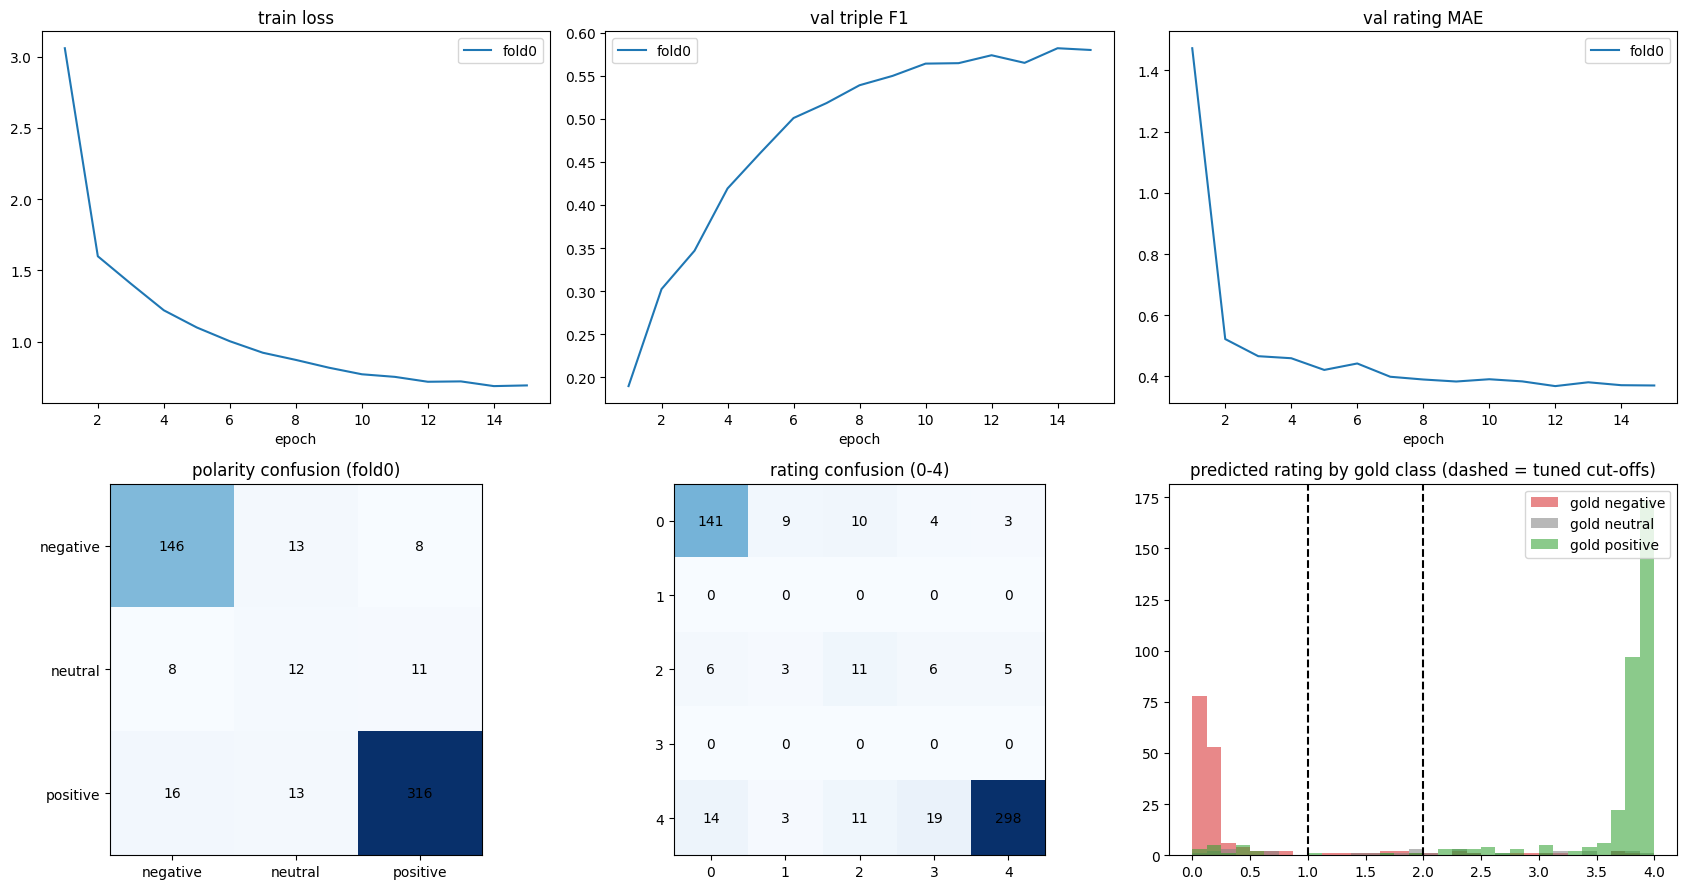

In [10]:
summary = pd.DataFrame([{**{"split": r["name"]}, **r["S"]} for r in results]).set_index("split")
head = ["triple_P", "triple_R", "triple_F1", "triple_F1_untuned", "triple_macroF1_polarity", "triple5_F1", "pair_F1", "category_micro_F1", "category_macro_F1",
        "attribute_micro_F1", "attribute_macro_F1", "polarity_acc", "polarity_macroF1", "rating_acc", "rating_within1", "rating_MAE", "rating_RMSE",
        "rating_spearman", "rating_QWK", "conf_ECE", "sentence_exact_match", "best_epoch"]
print("per split:"); display(summary[head].round(4))
if len(results) > 1:
    print("mean +- std over folds:")
    display(pd.DataFrame({"mean": summary[head].mean(), "std": summary[head].std()}).round(4))
summary.to_csv(out_dir / "test_metrics_summary.csv")

fig, ax = plt.subplots(2, 3, figsize=(17, 9)); ax = ax.ravel()
for r in results:
    ax[0].plot(r["hist"]["epoch"], r["hist"]["train_total"], label=r["name"]); ax[1].plot(r["hist"]["epoch"], r["hist"]["val_triple_F1"], label=r["name"])
    ax[2].plot(r["hist"]["epoch"], r["hist"]["val_rating_MAE"], label=r["name"])
ax[0].set_title("train loss"); ax[1].set_title("val triple F1"); ax[2].set_title("val rating MAE")
for a in ax[:3]: a.legend(); a.set_xlabel("epoch")
def heat(a, cm, title):
    a.imshow(cm.values, cmap="Blues"); a.set_title(title)
    a.set_xticks(range(cm.shape[1])); a.set_xticklabels([c.replace("pred_", "") for c in cm.columns]); a.set_yticks(range(cm.shape[0])); a.set_yticklabels([c.replace("gold_", "") for c in cm.index])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]): a.text(j, i, cm.values[i, j], ha="center", va="center")
heat(ax[3], last["T"]["polarity_confusion"], f"polarity confusion ({last['name']})"); heat(ax[4], last["T"]["rating_confusion"], "rating confusion (0-4)")
ex_ = last["extra"]
for k, col in zip(range(P), ["tab:red", "tab:gray", "tab:green"]):
    ax[5].hist(ex_["rating"][ex_["gold3"] == k], bins=np.linspace(0, NR - 1, 33), alpha=.55, color=col, label=f"gold {polarities[k]}")
for v in (last["thr"]["lo"], last["thr"]["hi"]): ax[5].axvline(v, color="k", ls="--")
ax[5].set_title("predicted rating by gold class (dashed = tuned cut-offs)"); ax[5].legend()
plt.tight_layout(); plt.savefig(out_dir / "curves.png", dpi=120); plt.show()

## 10. Inference

`predict` returns, for each opinion, the category, attribute, expected rating, polarity, confidence and pair score. `load_bundle` reloads a saved checkpoint with its thresholds and labels.

On my three test sentences:
- "Super fast processor and a really nice graphics card." is positive (ratings about 3.9) for LAPTOP#OPERATION_PERFORMANCE, LAPTOP#GENERAL and CPU#OPERATION_PERFORMANCE, but the graphics card (GRAPHICS) is missed.
- "It works, nothing special." ends up neutral through the confidence rule: `r` = 2.1 is just above `hi` = 2.0, but only 17% of the probability is on ratings 3-4, below `min_conf` = 0.5. The printed confidence is that 0.17.
- "The battery lasts 10 hours but the screen is dim." goes wrong: the battery comes out negative (rating 0.15) and the screen is missed. Probably the "dim" part pulls the whole sentence negative, since every head reads the same pooled vector.

In [11]:
@torch.no_grad()
def predict(texts, model, tok, thr, prev=None, nxt=None):
    if isinstance(texts, str): texts = [texts]
    model.eval()
    pairs = [((prev[i] if prev else "") + " " + (nxt[i] if nxt else "")).strip() or texts[i] for i in range(len(texts))] if CFG.use_context else None
    enc = tok(texts, pairs, truncation=True, max_length=CFG.max_length, padding=True, return_tensors="pt") if pairs else \
          tok(texts, truncation=True, max_length=CFG.max_length, padding=True, return_tensors="pt")
    o = model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
    pair_p = o["pair_logits"].float().sigmoid().cpu().numpy(); rat_p = o["rating_logits"].float().softmax(-1).cpu().numpy()
    r, lab, conf = decode(rat_p, thr["lo"], thr["hi"], thr["min_conf"])
    res = []
    for n, t in enumerate(texts):
        ops = [dict(category=categories[ci], attribute=attributes[ai], rating=round(float(r[n, ci, ai]), 2), polarity=polarities[int(lab[n, ci, ai])],
                    confidence=round(float(conf[n, ci, ai]), 3), pair_score=round(float(pair_p[n, ci, ai]), 3))
               for ci, ai in zip(*np.where(pair_p[n] >= thr["pair"]))]
        res.append(dict(text=t, opinions=sorted(ops, key=lambda x: -x["pair_score"])))
    return res

def load_bundle(path):
    ck = torch.load(path, map_location=device, weights_only=False); mc = ck["model_config"]
    tok = AutoTokenizer.from_pretrained(mc["model_name"], trust_remote_code=mc["trust_remote_code"])
    if tok.pad_token is None: tok.pad_token = tok.eos_token or tok.unk_token
    m = ABSAModel(mc["model_name"], len(ck["labels"]["categories"]), len(ck["labels"]["attributes"]), mc["n_ratings"],
                  mc["dropout"], mc["pooling"], mc["trust_remote_code"])
    m.load_state_dict(ck["state_dict"]); return m.to(device).eval(), tok, ck["thresholds"], ck["labels"]

demo = ["The battery lasts 10 hours but the screen is dim.", "Super fast processor and a really nice graphics card.", "It works, nothing special."]
for r in predict(demo, last["model"], last["tok"], last["thr"]):
    print(json.dumps(r, indent=1))

{
 "text": "The battery lasts 10 hours but the screen is dim.",
 "opinions": [
  {
   "category": "BATTERY",
   "attribute": "OPERATION_PERFORMANCE",
   "rating": 0.15,
   "polarity": "negative",
   "confidence": 0.863,
   "pair_score": 0.989
  },
  {
   "category": "LAPTOP",
   "attribute": "OPERATION_PERFORMANCE",
   "rating": 0.3,
   "polarity": "negative",
   "confidence": 0.804,
   "pair_score": 0.923
  }
 ]
}
{
 "text": "Super fast processor and a really nice graphics card.",
 "opinions": [
  {
   "category": "LAPTOP",
   "attribute": "OPERATION_PERFORMANCE",
   "rating": 3.87,
   "polarity": "positive",
   "confidence": 1.0,
   "pair_score": 0.987
  },
  {
   "category": "LAPTOP",
   "attribute": "GENERAL",
   "rating": 3.92,
   "polarity": "positive",
   "confidence": 1.0,
   "pair_score": 0.941
  },
  {
   "category": "CPU",
   "attribute": "OPERATION_PERFORMANCE",
   "rating": 3.86,
   "polarity": "positive",
   "confidence": 0.99,
   "pair_score": 0.873
  }
 ]
}
{
 "text": "

## 11. Files produced and download

Everything is in `absa_results/` and gets downloaded as one zip. The two checkpoints are about 130 MB each. The rest are small CSV / JSON files, the log and the plot.

In [12]:
print(f"results folder: {out_dir.resolve()}")
for p in sorted(out_dir.iterdir()): print(f"  {p.name:55s} {p.stat().st_size/1024:10.1f} KB")
zip_path = shutil.make_archive("absa_results", "zip", out_dir)
try:
    from google.colab import files; files.download(zip_path)
except ImportError:
    print("zip at", zip_path)

results folder: /content/absa_results
  best_fold0.pt                                             133371.0 KB
  config.json                                                    0.8 KB
  curves.png                                                   124.8 KB
  fold0_by_attribute.csv                                         0.6 KB
  fold0_by_category.csv                                          0.9 KB
  fold0_confidence_coverage.csv                                  0.3 KB
  fold0_polarity_confusion.csv                                   0.1 KB
  fold0_polarity_given_gold_pair.csv                             0.2 KB
  fold0_rating_by_gold.csv                                       0.2 KB
  fold0_rating_confusion.csv                                     0.1 KB
  fold0_triple_by_polarity.csv                                   0.2 KB
  history_fold0.csv                                              5.5 KB
  labels.json                                                    0.7 KB
  last_fold0.pt           

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>